In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/Global E-Commerce Sales and Customer Data.csv')

In [ ]:
df.head()

,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,1/2/2023,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,1/2/2023,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,1/3/2023,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,1/3/2023,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,1/5/2023,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   object 
 1   Order_Date        2000 non-null   object 
 2   Customer_Name     2000 non-null   object 
 3   Customer_Segment  2000 non-null   object 
 4   Country           2000 non-null   object 
 5   Region            2000 non-null   object 
 6   Product_Category  2000 non-null   object 
 7   Product_Name      2000 non-null   object 
 8   Quantity          2000 non-null   int64  
 9   Unit_Price        2000 non-null   float64
 10  Discount_Percent  2000 non-null   int64  
 11  Total_Sales       2000 non-null   float64
 12  Shipping_Cost     2000 non-null   float64
 13  Profit            2000 non-null   float64
 14  Payment_Method    2000 non-null   object 
dtypes: float64(4), int64(2), object(9)
memory usage: 234.5+ KB


In [ ]:
df.shape

(2000, 15)

In [ ]:
df.columns.tolist()

['Order_ID',
 'Order_Date',
 'Customer_Name',
 'Customer_Segment',
 'Country',
 'Region',
 'Product_Category',
 'Product_Name',
 'Quantity',
 'Unit_Price',
 'Discount_Percent',
 'Total_Sales',
 'Shipping_Cost',
 'Profit',
 'Payment_Method']

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,2000.0,3.55750,2.704506,1.00,2.0000,3.000,5.0000,15.00
Unit_Price,2000.0,73.32949,79.311014,3.03,18.7575,46.420,90.2500,472.56
Discount_Percent,2000.0,8.57250,7.261274,0.00,0.0000,10.000,15.0000,30.00
Total_Sales,2000.0,242.27967,382.583802,2.42,41.2275,113.125,266.5525,3813.98
Shipping_Cost,2000.0,12.90212,5.223190,5.52,9.4575,11.845,14.9200,40.44
Profit,2000.0,79.43616,137.573593,-11.28,6.8650,32.830,90.2975,1373.63


In [ ]:
#statistik kolom kategorikal
df.describe(include='object').T

,count,unique,top,freq
Order_ID,2000,2000,ORD-11409,1
Order_Date,2000,907,12/11/2023,8
Customer_Name,2000,1534,Chen Patel,5
Customer_Segment,2000,3,Consumer,1006
Country,2000,20,Mexico,203
Region,2000,5,North America,578
Product_Category,2000,4,Technology,567
Product_Name,2000,40,Wireless Ergonomic Mouse,67
Payment_Method,2000,4,Credit Card,797


Missing Value

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_Name,0
Customer_Segment,0
Country,0
Region,0
Product_Category,0
Product_Name,0
Quantity,0
Unit_Price,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#Cek unik value
for col in df.select_dtypes(include='object').columns:
    print(f'\n{col}')
    print(df[col].value_counts())


Order_ID
Order_ID
ORD-11409    1
ORD-11286    1
ORD-10938    1
ORD-10077    1
ORD-11034    1
            ..
ORD-11454    1
ORD-10467    1
ORD-10325    1
ORD-11244    1
ORD-11121    1
Name: count, Length: 2000, dtype: int64

Order_Date
Order_Date
12/11/2023    8
12/7/2023     7
10/9/2024     7
5/27/2024     7
12/26/2023    7
             ..
12/2/2024     1
12/1/2024     1
11/29/2024    1
12/27/2025    1
12/18/2025    1
Name: count, Length: 907, dtype: int64

Customer_Name
Customer_Name
Chen Patel               5
Felix Smith              4
Wei Li                   4
Sakura Thomas            4
Fatima Williams          4
                        ..
Christopher Johansson    1
Ingrid Suzuki            1
Felix Thomas             1
Clara Taylor             1
John Johansson           1
Name: count, Length: 1534, dtype: int64

Customer_Segment
Customer_Segment
Consumer       1006
Corporate       623
Home Office     371
Name: count, dtype: int64

Country
Country
Mexico            203
United State

In [ ]:
validation = {
    'Quantity <= 0': (df['Quantity'] <= 0).sum(),
    'Unit Price <= 0': (df['Unit_Price'] <= 0).sum(),
    'Discount < 0': (df['Discount_Percent'] < 0).sum(),
    'Discount > 100': (df['Discount_Percent'] > 100).sum(),
    'Total Sales <= 0': (df['Total_Sales'] <= 0).sum(),
    'Negative Profit': (df['Profit'] < 0).sum()
}

pd.Series(validation)

,0
Quantity <= 0,0
Unit Price <= 0,0
Discount < 0,0
Discount > 100,0
Total Sales <= 0,0
Negative Profit,272


In [ ]:
df['Calculated_Sales'] = (
    df['Quantity'] *
    df['Unit_Price'] *
    (1 - df['Discount_Percent'] / 100)
)

df[['Quantity', 'Unit_Price', 'Discount_Percent',
    'Total_Sales', 'Calculated_Sales']].head(10)

,Quantity,Unit_Price,Discount_Percent,Total_Sales,Calculated_Sales
0,3,99.43,0,298.29,298.2900
1,4,97.93,20,313.38,313.3760
2,2,10.74,0,21.48,21.4800
3,2,61.86,15,105.16,105.1620
4,4,330.67,20,1058.14,1058.1440
5,1,61.93,10,55.74,55.7370
6,2,15.03,5,28.56,28.5570
7,2,33.91,10,61.04,61.0380
8,2,334.11,5,634.81,634.8090
9,1,58.77,5,55.83,55.8315


In [ ]:
df['Sales_Match'] = np.isclose(
    df['Total_Sales'],
    df['Calculated_Sales'],
    atol=0.01
)

In [ ]:
df['Sales_Match'].value_counts()

,count
Sales_Match,
True,2000


KPI Utama

In [ ]:
#Total Sales
total_sales = df['Total_Sales'].sum()

print(f"Total Sales: ${total_sales:,.2f}")

Total Sales: $484,559.34


In [ ]:
#Total Profit
total_profit = df['Profit'].sum()

print(f"Total Profit: ${total_profit:,.2f}")

Total Profit: $158,872.32


In [ ]:
#Total Orders
total_orders = df['Order_ID'].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 2,000


In [ ]:
#Total Customers
total_customers = df['Customer_Name'].nunique()

print(f"Total Customers: {total_customers:,}")

Total Customers: 1,534


In [ ]:
#Total Quantity Sold
total_quantity = df['Quantity'].sum()

print(f"Total Quantity Sold: {total_quantity:,}")

Total Quantity Sold: 7,115


In [ ]:
#Average Order Value (AOV)
average_order_value = total_sales / total_orders

print(f"Average Order Value: ${average_order_value:,.2f}")

Average Order Value: $242.28


In [ ]:
#Overall Profit Margin
profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")

Overall Profit Margin: 32.79%


In [ ]:
print("===== KEY PERFORMANCE INDICATORS =====")
print(f"Total Sales          : ${total_sales:,.2f}")
print(f"Total Profit         : ${total_profit:,.2f}")
print(f"Total Orders         : {total_orders:,}")
print(f"Total Customers      : {total_customers:,}")
print(f"Total Quantity Sold  : {total_quantity:,}")
print(f"Average Order Value  : ${average_order_value:,.2f}")
print(f"Profit Margin        : {profit_margin:.2f}%")

===== KEY PERFORMANCE INDICATORS =====
Total Sales          : $484,559.34
Total Profit         : $158,872.32
Total Orders         : 2,000
Total Customers      : 1,534
Total Quantity Sold  : 7,115
Average Order Value  : $242.28
Profit Margin        : 32.79%


In [ ]:
# Ensure Order_Date is datetime and create Month_Year
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month_Year'] = df['Order_Date'].dt.to_period('M')

# Monthly Sales Trend
monthly_sales = (
    df.groupby('Month_Year')['Total_Sales']
    .sum()
    .reset_index()
)

# Convert Month_Year to string for nicer output/plotting if needed
monthly_sales['Month_Year'] = monthly_sales['Month_Year'].astype(str)
monthly_sales.head()

,Month_Year,Total_Sales
0,2023-01,11275.20
1,2023-02,16943.67
2,2023-03,16056.45
3,2023-04,12185.00
4,2023-05,8218.47


Monthly sales Trend

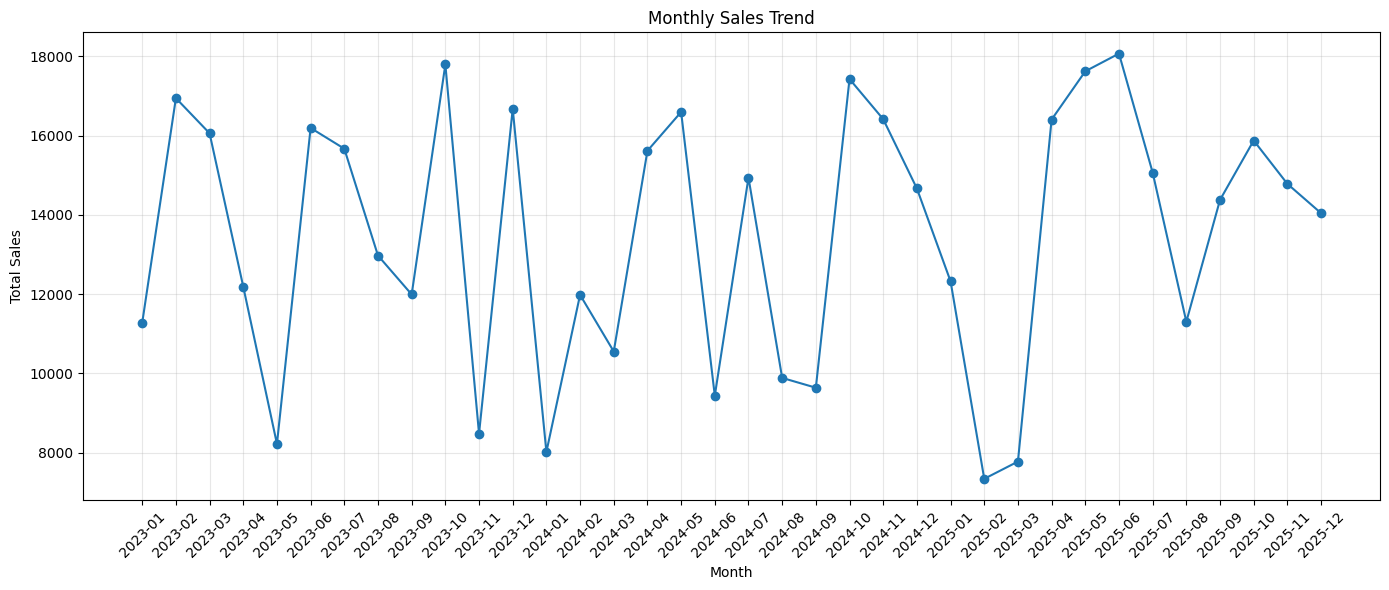

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Month_Year'],
    monthly_sales['Total_Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Monthly Profit Trend

In [ ]:
monthly_sales.sort_values(
    by='Total_Sales',
    ascending=False
).head(10)

,Month_Year,Total_Sales
29,2025-06,18068.09
9,2023-10,17794.60
28,2025-05,17621.80
21,2024-10,17426.05
1,2023-02,16943.67
11,2023-12,16674.44
16,2024-05,16594.20
22,2024-11,16413.27
27,2025-04,16403.60
5,2023-06,16191.61


In [ ]:
monthly_profit = (
    df.groupby('Month_Year')['Profit']
    .sum()
    .reset_index()
)

monthly_profit.head()

,Month_Year,Profit
0,2023-01,3573.01
1,2023-02,5980.06
2,2023-03,5718.77
3,2023-04,3994.25
4,2023-05,2591.86


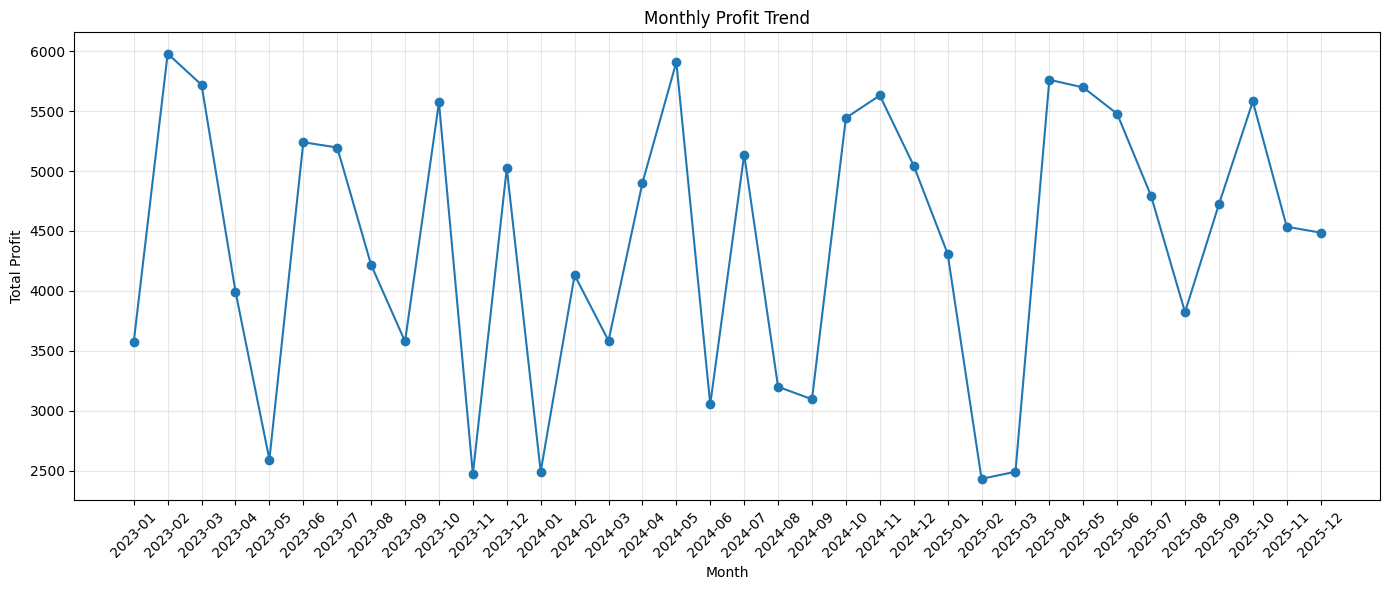

In [ ]:
# Convert Month_Year to string to prevent Matplotlib Period TypeError
monthly_profit['Month_Year'] = monthly_profit['Month_Year'].astype(str)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_profit['Month_Year'],
    monthly_profit['Profit'],
    marker='o'
)

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
monthly_profit.sort_values(
    by='Profit',
    ascending=False
).head(10)

,Month_Year,Profit
1,2023-02,5980.06
16,2024-05,5909.30
27,2025-04,5761.61
2,2023-03,5718.77
28,2025-05,5697.41
22,2024-11,5630.78
33,2025-10,5580.52
9,2023-10,5573.05
29,2025-06,5477.02
21,2024-10,5443.33


In [ ]:
# Extract Year from Order_Date
df['Year'] = df['Order_Date'].dt.year

# Sales & Profit by Year
yearly_performance = (
    df.groupby('Year')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

yearly_performance

,Year,Total_Sales,Total_Profit,Total_Orders
0,2023,164443.45,53153.74,670
1,2024,155150.73,51616.11,649
2,2025,164965.16,54102.47,681


In [ ]:
# Growth Sales Per Tahun
yearly_performance['Sales_Growth_%'] = (
    yearly_performance['Total_Sales']
    .pct_change() * 100
)

yearly_performance

,Year,Total_Sales,Total_Profit,Total_Orders,Sales_Growth_%
0,2023,164443.45,53153.74,670,NaN
1,2024,155150.73,51616.11,649,-5.651013
2,2025,164965.16,54102.47,681,6.325739


Product Category Performance

In [ ]:
category_performance = (
    df.groupby('Product_Category')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Quantity_Sold=('Quantity', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

category_performance

,Product_Category,Total_Sales,Total_Profit,Quantity_Sold,Total_Orders
1,Furniture,256274.68,81171.57,1806,507
3,Technology,139518.22,48268.65,2017,567
0,Clothing & Accessories,69375.63,26112.94,1551,413
2,Office Supplies,19390.81,3319.16,1741,513


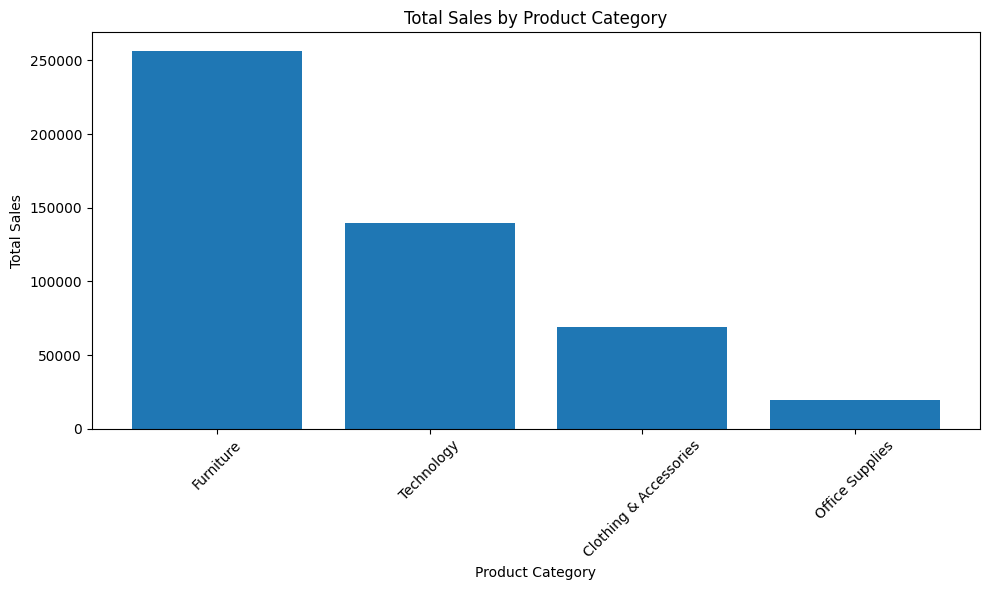

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_performance['Product_Category'],
    category_performance['Total_Sales']
)

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

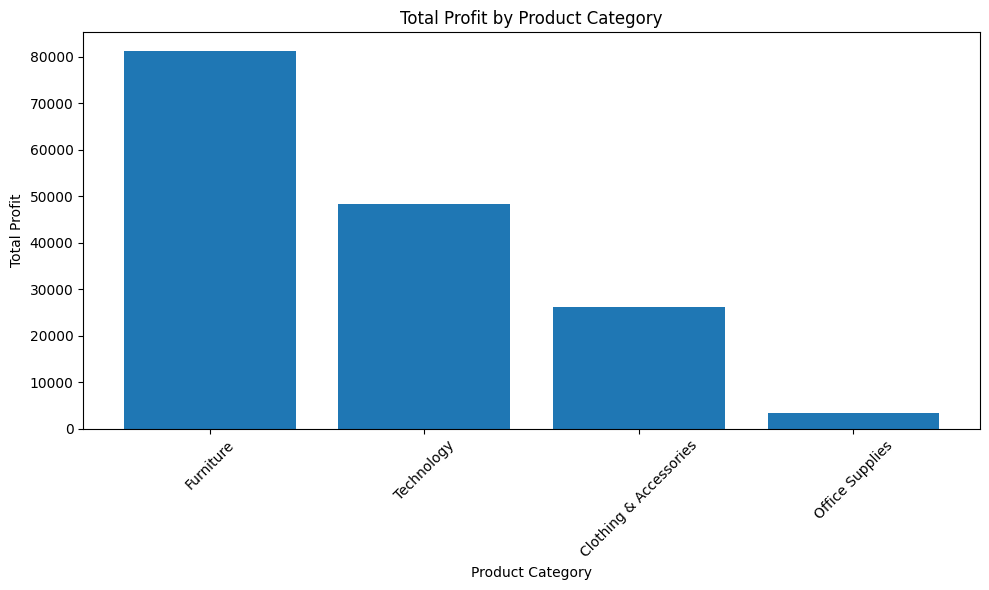

In [ ]:
category_profit = category_performance.sort_values(
    'Total_Profit',
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    category_profit['Product_Category'],
    category_profit['Total_Profit']
)

plt.title('Total Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#TOP 10 Product
top_products = (
    df.groupby('Product_Name')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Quantity_Sold=('Quantity', 'sum')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
    .head(10)
)

top_products

,Product_Name,Total_Sales,Total_Profit,Quantity_Sold
28,Standing Desk Converter,46614.22,14694.35,215
9,Ergonomic Office Chair,45405.15,15104.58,167
5,Corner L-Shaped Desk,41070.48,13663.00,146
18,Mesh Back Task Chair,38179.77,12820.11,213
37,Wireless Bluetooth Headphones,28258.70,10611.08,212
17,Mechanical Gaming Keyboard,24072.42,8381.19,227
10,Filing Cabinet 3-Drawer,23108.01,7041.80,170
12,Folding Table Portable,18663.13,5589.03,226
23,Portable External SSD 1TB,18065.30,6556.75,185
2,Bookshelf 5-Tier,17741.59,5490.57,154


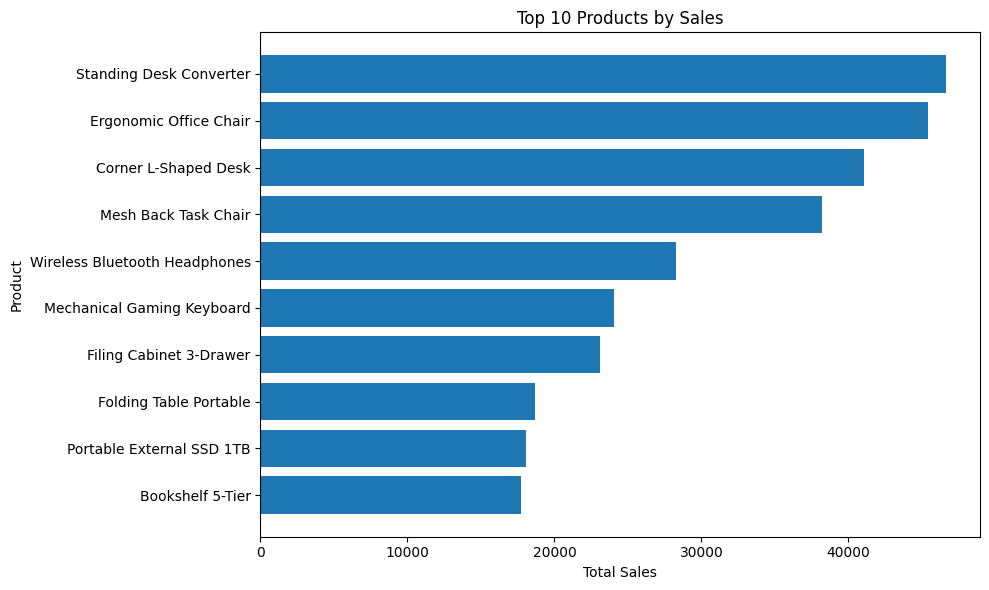

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_products['Product_Name'],
    top_products['Total_Sales']
)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#Customer Segment Analysis
segment_analysis = (
    df.groupby('Customer_Segment')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Total_Customers=('Customer_Name', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

segment_analysis

,Customer_Segment,Total_Sales,Total_Profit,Total_Orders,Total_Customers
0,Consumer,256287.74,87300.36,1006,864
1,Corporate,146050.39,44463.44,623,558
2,Home Office,82221.21,27108.52,371,355


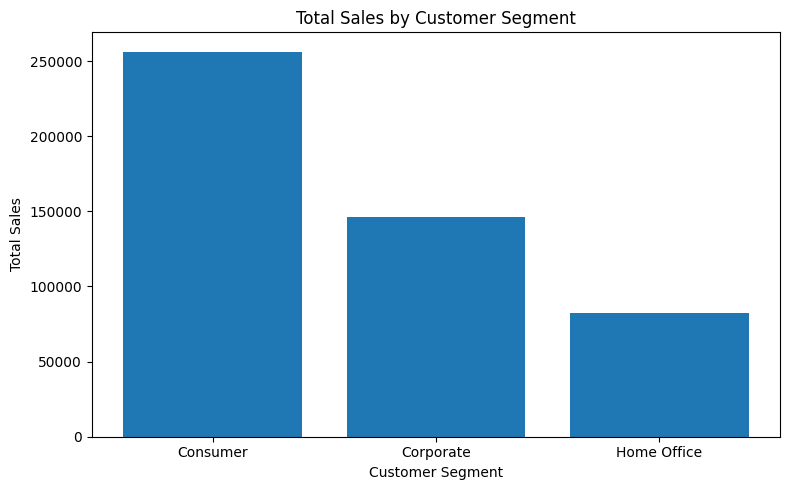

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_analysis['Customer_Segment'],
    segment_analysis['Total_Sales']
)

plt.title('Total Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [ ]:
#Top 10 Customer
top_customers = (
    df.groupby('Customer_Name')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Quantity_Purchased=('Quantity', 'sum')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
    .head(10)
)

top_customers

,Customer_Name,Total_Sales,Total_Profit,Total_Orders,Quantity_Purchased
1195,Priya Jackson,3836.46,1390.64,2,14
455,Hanna Jones,3813.98,1370.08,1,12
1315,Sarah Chen,3184.56,1153.99,2,17
800,Li Laurent,3007.62,1189.79,1,7
1024,Nadia Wang,2958.97,1001.81,3,19
1205,Priya Oliveira,2901.11,1054.26,1,10
418,Felix Thompson,2835.36,1115.05,1,6
857,Linda Weber,2762.40,657.86,1,10
737,Karen Sato,2738.18,884.82,2,11
873,Lucas Nilsson,2734.69,1016.19,2,12


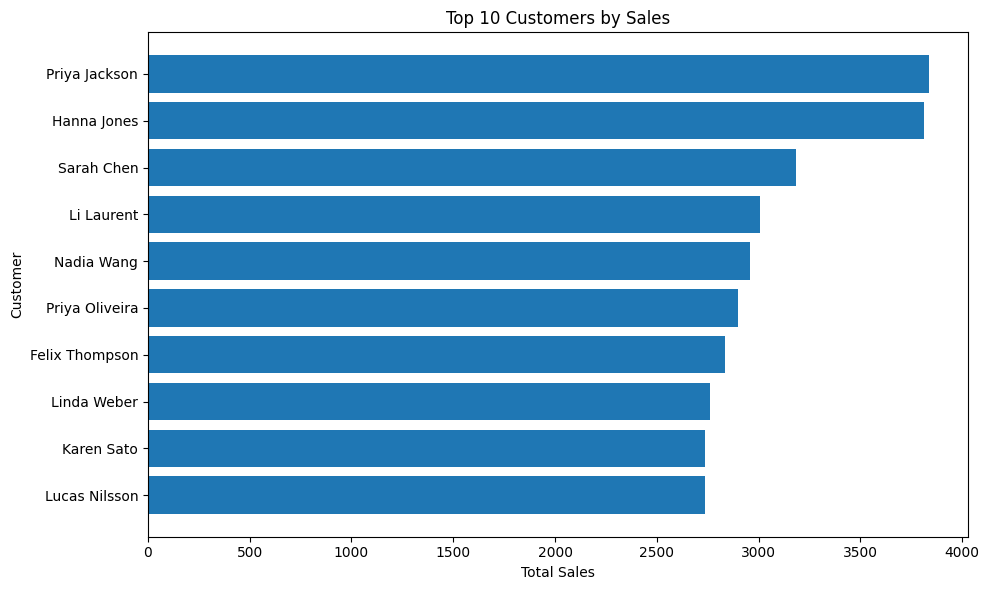

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_customers['Customer_Name'],
    top_customers['Total_Sales']
)

plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Customer')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#Geographic Analysis
country_analysis = (
    df.groupby('Country')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

country_analysis

,Country,Total_Sales,Total_Profit,Total_Orders
11,Mexico,47217.30,15949.44,203
3,Canada,45326.55,15320.95,179
19,United States,41332.53,13979.70,196
10,Japan,30950.19,9826.31,124
18,United Kingdom,30185.46,10185.32,106
7,Germany,28989.73,9518.07,95
4,China,28322.85,9028.07,109
9,Italy,27484.38,9125.06,105
6,France,26616.81,8973.46,105
1,Australia,25287.72,8072.37,107


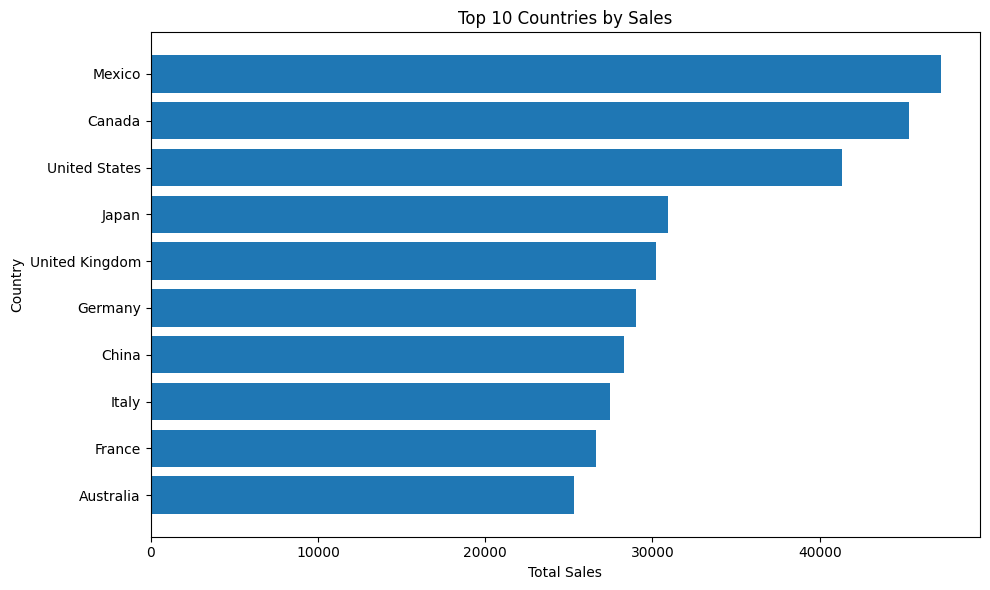

In [ ]:
#Top 10 countries by sales
top_countries = country_analysis.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries['Country'],
    top_countries['Total_Sales']
)

plt.title('Top 10 Countries by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Country')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

REGION PERFOMANCE

In [ ]:
region_analysis = (
    df.groupby('Region')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Quantity_Sold=('Quantity', 'sum')
    )
    .reset_index()
    .sort_values('Total_Sales', ascending=False)
)

region_analysis

,Region,Total_Sales,Total_Profit,Total_Orders,Quantity_Sold
1,Europe,137006.20,45672.16,503,1822
3,North America,133876.38,45250.09,578,1996
0,Asia Pacific,121707.51,39116.61,520,1909
4,South America,46051.13,14680.98,191,658
2,Middle East & Africa,45918.12,14152.48,208,730


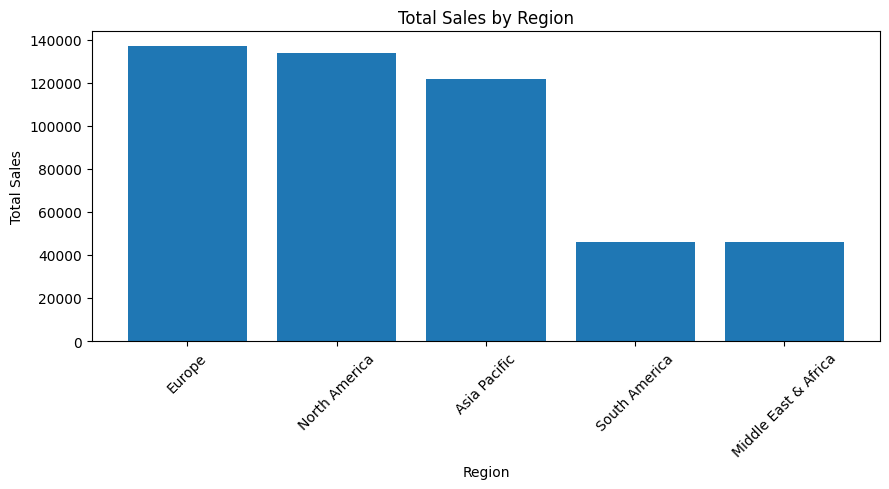

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    region_analysis['Region'],
    region_analysis['Total_Sales']
)

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Payment Method Analysis

In [ ]:
payment_analysis = (
    df.groupby('Payment_Method')
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Total_Sales=('Total_Sales', 'sum')
    )
    .reset_index()
    .sort_values('Total_Orders', ascending=False)
)

payment_analysis

,Payment_Method,Total_Orders,Total_Sales
2,Credit Card,797,192717.89
3,PayPal,609,143112.87
1,Cash on Delivery,301,77129.54
0,Bank Transfer,293,71599.04


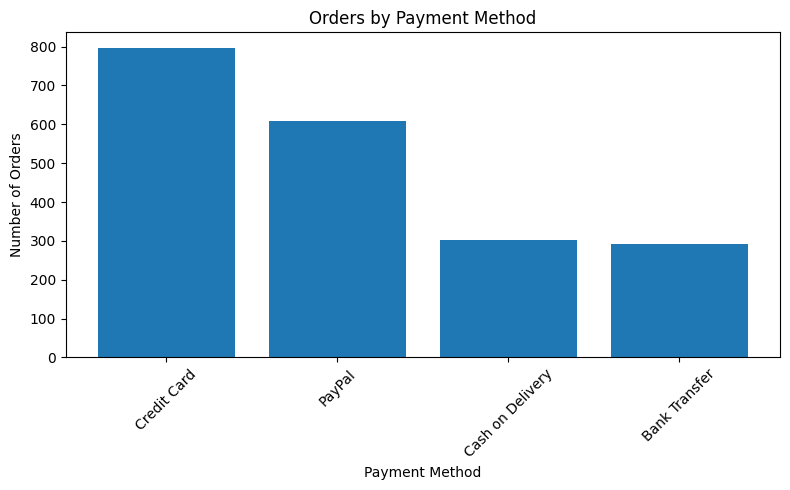

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_analysis['Payment_Method'],
    payment_analysis['Total_Orders']
)

plt.title('Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Discunt Analysis

In [ ]:
df['Discount_Percent'].describe()

,Discount_Percent
count,2000.000000
mean,8.572500
std,7.261274
min,0.000000
25%,0.000000
50%,10.000000
75%,15.000000
max,30.000000


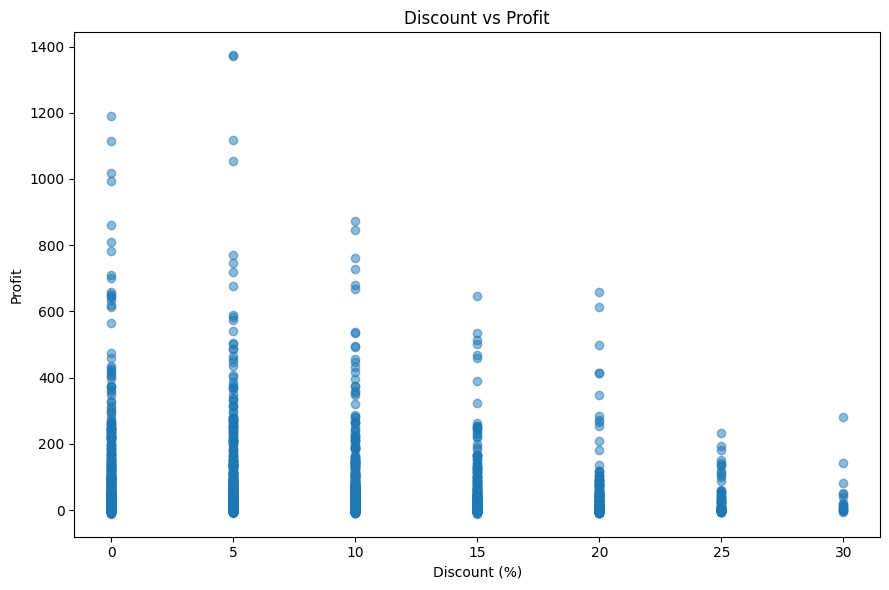

In [ ]:
#Dsicount vs profit
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Discount_Percent'],
    df['Profit'],
    alpha=0.5
)

plt.title('Discount vs Profit')
plt.xlabel('Discount (%)')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

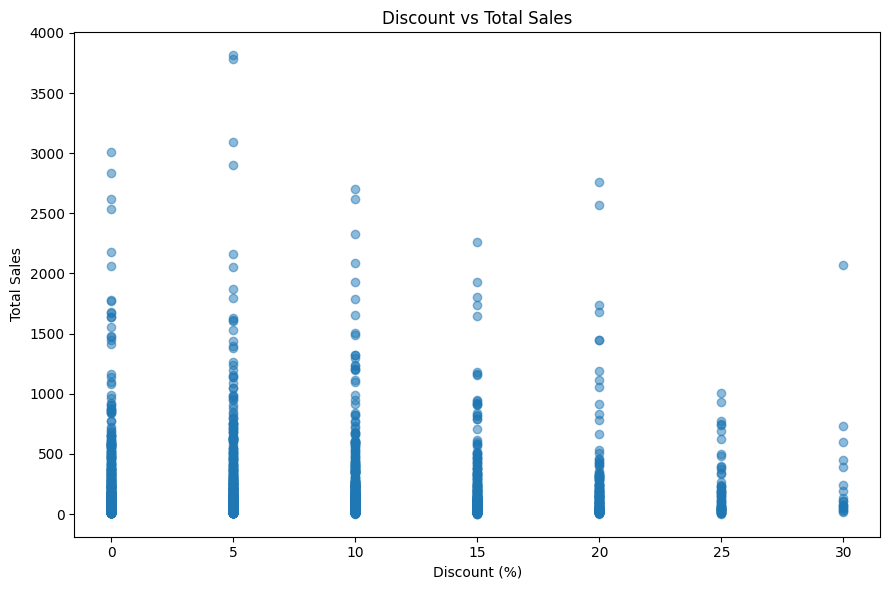

In [ ]:
#Discount vs sales
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Discount_Percent'],
    df['Total_Sales'],
    alpha=0.5
)

plt.title('Discount vs Total Sales')
plt.xlabel('Discount (%)')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [ ]:
#Korelasi Discount, sales & Profit
correlation = df[
    ['Discount_Percent', 'Total_Sales', 'Profit', 'Shipping_Cost', 'Quantity']
].corr()

correlation

,Discount_Percent,Total_Sales,Profit,Shipping_Cost,Quantity
Discount_Percent,1.000000,-0.045900,-0.141340,0.015693,0.005010
Total_Sales,-0.045900,1.000000,0.979217,0.385902,0.503233
Profit,-0.141340,0.979217,1.000000,0.363832,0.503155
Shipping_Cost,0.015693,0.385902,0.363832,1.000000,0.766924
Quantity,0.005010,0.503233,0.503155,0.766924,1.000000


In [ ]:
print(
    "Correlation Discount vs Sales:",
    round(df['Discount_Percent'].corr(df['Total_Sales']), 3)
)

print(
    "Correlation Discount vs Profit:",
    round(df['Discount_Percent'].corr(df['Profit']), 3)
)

Correlation Discount vs Sales: -0.046
Correlation Discount vs Profit: -0.141


Profitability Analysis

In [ ]:
product_performance = (
    df.groupby('Product_Name')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Quantity_Sold=('Quantity', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

product_performance['Profit_Margin_%'] = (
    product_performance['Total_Profit'] /
    product_performance['Total_Sales'] * 100
)

product_performance.sort_values(
    'Total_Sales',
    ascending=False
).head(10)

,Product_Name,Total_Sales,Total_Profit,Quantity_Sold,Total_Orders,Profit_Margin_%
28,Standing Desk Converter,46614.22,14694.35,215,57,31.523321
9,Ergonomic Office Chair,45405.15,15104.58,167,42,33.266226
5,Corner L-Shaped Desk,41070.48,13663.00,146,39,33.267203
18,Mesh Back Task Chair,38179.77,12820.11,213,59,33.578280
37,Wireless Bluetooth Headphones,28258.70,10611.08,212,56,37.549781
17,Mechanical Gaming Keyboard,24072.42,8381.19,227,58,34.816566
10,Filing Cabinet 3-Drawer,23108.01,7041.80,170,45,30.473416
12,Folding Table Portable,18663.13,5589.03,226,57,29.946906
23,Portable External SSD 1TB,18065.30,6556.75,185,55,36.294720
2,Bookshelf 5-Tier,17741.59,5490.57,154,55,30.947452


In [ ]:
#Top 10 Product by profit
top_profit_products = (
    product_performance
    .sort_values('Total_Profit', ascending=False)
    .head(10)
)

top_profit_products

,Product_Name,Total_Sales,Total_Profit,Quantity_Sold,Total_Orders,Profit_Margin_%
9,Ergonomic Office Chair,45405.15,15104.58,167,42,33.266226
28,Standing Desk Converter,46614.22,14694.35,215,57,31.523321
5,Corner L-Shaped Desk,41070.48,13663.00,146,39,33.267203
18,Mesh Back Task Chair,38179.77,12820.11,213,59,33.578280
37,Wireless Bluetooth Headphones,28258.70,10611.08,212,56,37.549781
17,Mechanical Gaming Keyboard,24072.42,8381.19,227,58,34.816566
10,Filing Cabinet 3-Drawer,23108.01,7041.80,170,45,30.473416
23,Portable External SSD 1TB,18065.30,6556.75,185,55,36.294720
3,Business Casual Blazer,14327.72,6004.33,160,40,41.907086
20,Noise Cancelling Earbuds,16119.60,5973.01,138,48,37.054331


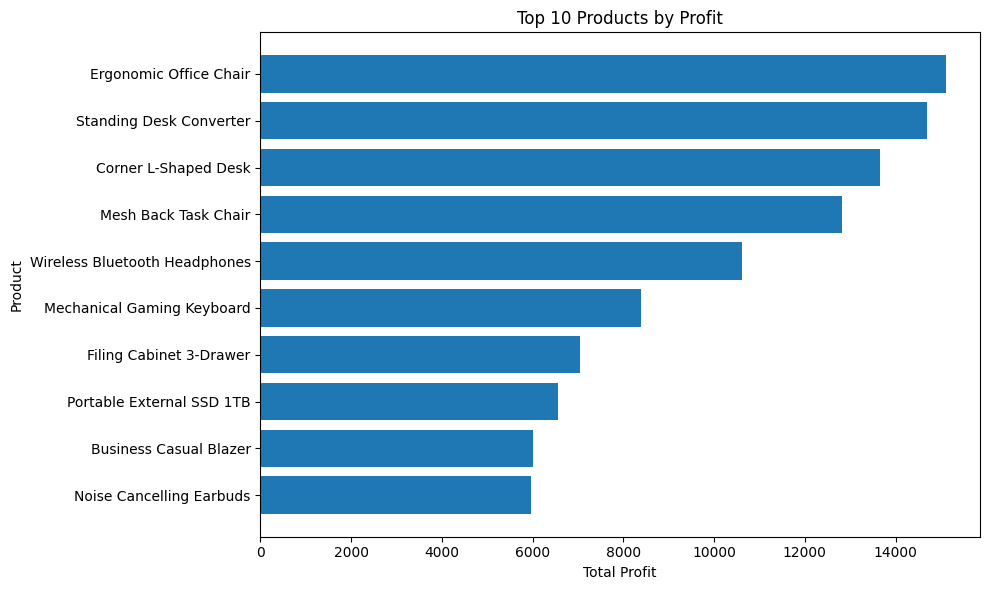

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_profit_products['Product_Name'],
    top_profit_products['Total_Profit']
)

plt.title('Top 10 Products by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Product')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#Identifikasi Transaksi loss
loss_transactions = df[df['Profit'] < 0]

print("Number of Loss Transactions:", len(loss_transactions))
print(
    "Percentage of Loss Transactions:",
    round(len(loss_transactions) / len(df) * 100, 2),
    "%"
)

Number of Loss Transactions: 272
Percentage of Loss Transactions: 13.6 %


In [ ]:
loss_transactions[
    [
        'Order_ID',
        'Product_Name',
        'Product_Category',
        'Total_Sales',
        'Discount_Percent',
        'Shipping_Cost',
        'Profit'
    ]
].head(10)

,Order_ID,Product_Name,Product_Category,Total_Sales,Discount_Percent,Shipping_Cost,Profit
11,ORD-11499,Paper Clips Box 500pc,Office Supplies,21.06,10,12.61,-2.08
14,ORD-10793,Tape Dispenser Heavy Duty,Office Supplies,15.82,0,9.16,-0.46
20,ORD-10686,Whiteboard Markers Set 8,Office Supplies,37.16,25,20.73,-5.87
23,ORD-10846,Sticky Notes Multicolor 6-Pack,Office Supplies,21.68,5,15.26,-3.85
31,ORD-11723,Stapler Full-Size,Office Supplies,7.26,15,7.97,-4.55
32,ORD-10408,Paper Clips Box 500pc,Office Supplies,16.21,5,9.30,-0.77
46,ORD-11858,Binder Clips Assorted 48pc,Office Supplies,24.65,5,17.04,-4.07
53,ORD-11430,Paper Clips Box 500pc,Office Supplies,4.30,10,11.84,-9.69
57,ORD-10384,Sports Water Bottle 750ml,Clothing & Accessories,8.96,0,11.08,-6.60
62,ORD-10322,Paper Clips Box 500pc,Office Supplies,8.67,10,10.44,-6.10


In [ ]:
#Produk dengan Profit Margin Terendah
lowest_margin_products = (
    product_performance[
        product_performance['Total_Sales'] > 0
    ]
    .sort_values('Profit_Margin_%')
    .head(10)
)

lowest_margin_products[
    [
        'Product_Name',
        'Total_Sales',
        'Total_Profit',
        'Profit_Margin_%'
    ]
]

,Product_Name,Total_Sales,Total_Profit,Profit_Margin_%
21,Paper Clips Box 500pc,901.89,-79.95,-8.864717
13,Highlighters Neon Pack 6,942.61,-0.37,-0.039253
30,Sticky Notes Multicolor 6-Pack,1072.27,61.90,5.772800
1,Binder Clips Assorted 48pc,1924.59,214.49,11.144711
0,Ballpoint Pen Pack 12,1760.36,254.45,14.454430
36,Whiteboard Markers Set 8,2090.67,311.95,14.921054
7,Desk Calendar 2025,2481.21,489.92,19.745205
29,Stapler Full-Size,2622.15,544.94,20.782183
8,Desk Organizer Set,5593.62,1349.77,24.130527
19,Monitor Riser Wood,8131.41,2010.94,24.730520


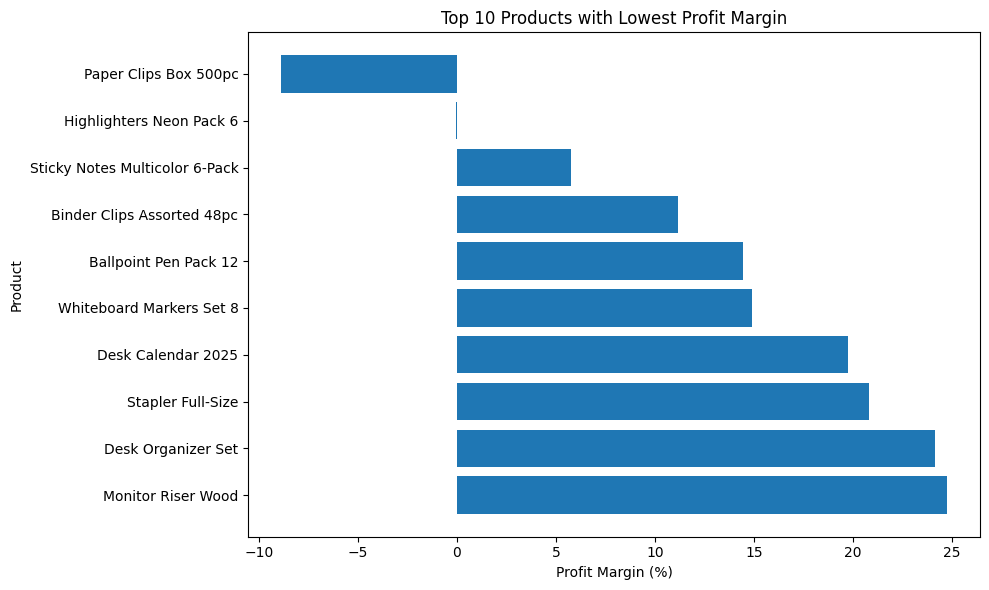

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    lowest_margin_products['Product_Name'],
    lowest_margin_products['Profit_Margin_%']
)

plt.title('Top 10 Products with Lowest Profit Margin')
plt.xlabel('Profit Margin (%)')
plt.ylabel('Product')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#Shipping cost Analysis
shipping_profit_corr = df['Shipping_Cost'].corr(df['Profit'])

print(
    "Correlation Shipping Cost vs Profit:",
    round(shipping_profit_corr, 3)
)

Correlation Shipping Cost vs Profit: 0.364


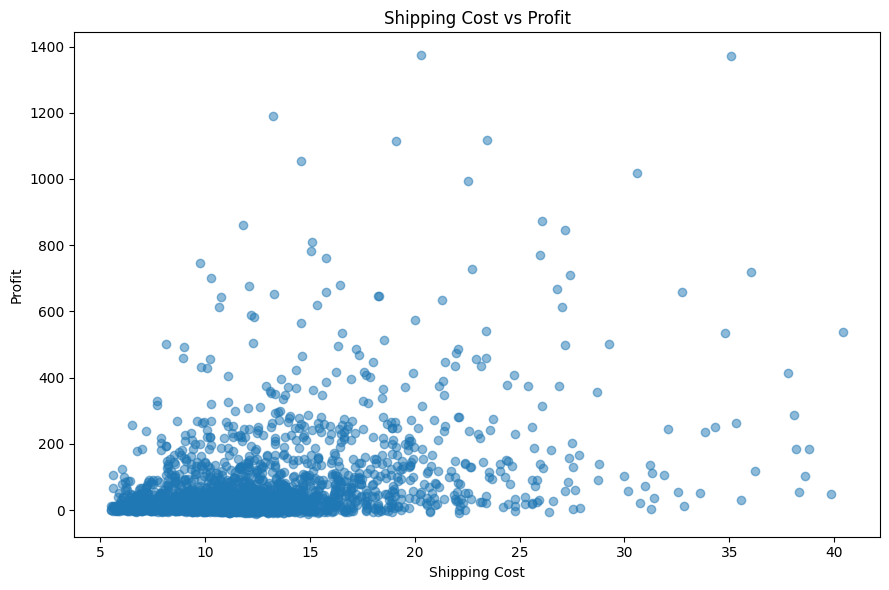

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Shipping_Cost'],
    df['Profit'],
    alpha=0.5
)

plt.title('Shipping Cost vs Profit')
plt.xlabel('Shipping Cost')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

In [ ]:
#Profit Margin per Category
category_margin = (
    df.groupby('Product_Category')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum')
    )
    .reset_index()
)

category_margin['Profit_Margin_%'] = (
    category_margin['Total_Profit'] /
    category_margin['Total_Sales'] * 100
)

category_margin = category_margin.sort_values(
    'Profit_Margin_%',
    ascending=False
)

category_margin

,Product_Category,Total_Sales,Total_Profit,Profit_Margin_%
0,Clothing & Accessories,69375.63,26112.94,37.639932
3,Technology,139518.22,48268.65,34.596664
1,Furniture,256274.68,81171.57,31.673660
2,Office Supplies,19390.81,3319.16,17.117181


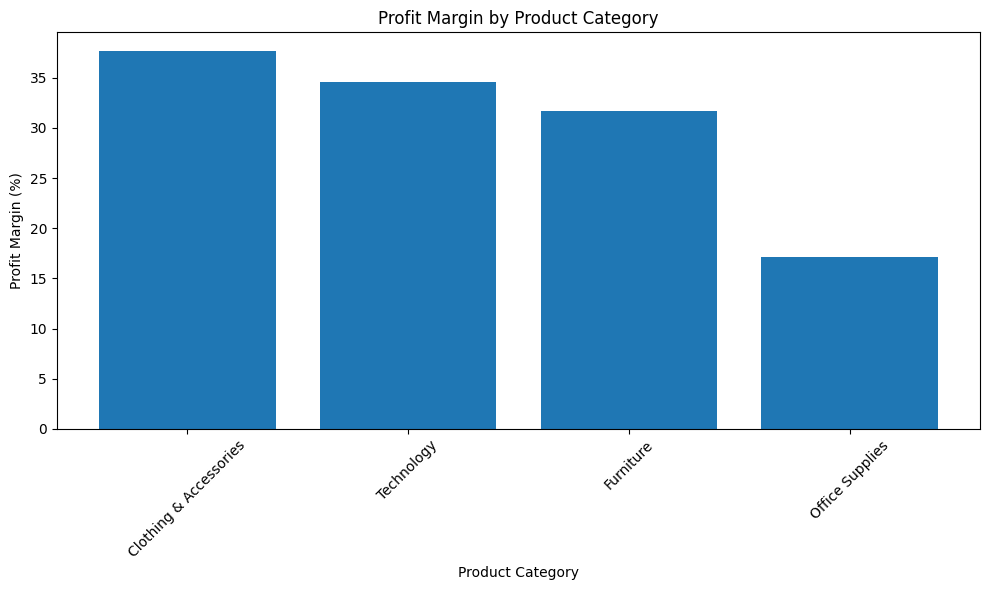

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_margin['Product_Category'],
    category_margin['Profit_Margin_%']
)

plt.title('Profit Margin by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Profit Margin (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Discount Level Analysis

In [ ]:
df['Discount_Level'] = pd.cut(
    df['Discount_Percent'],
    bins=[-1, 5, 10, 20, 30, 100],
    labels=[
        '0-5%',
        '6-10%',
        '11-20%',
        '21-30%',
        '>30%'
    ]
)

In [ ]:
discount_analysis = (
    df.groupby(
        'Discount_Level',
        observed=True
    )
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

discount_analysis['Profit_Margin_%'] = (
    discount_analysis['Total_Profit'] /
    discount_analysis['Total_Sales'] * 100
)

discount_analysis

,Discount_Level,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
0,0-5%,261418.45,96834.43,991,37.041926
1,6-10%,103136.11,32932.51,443,31.931115
2,11-20%,101304.20,25808.48,481,25.476219
3,21-30%,18700.58,3296.90,85,17.629934


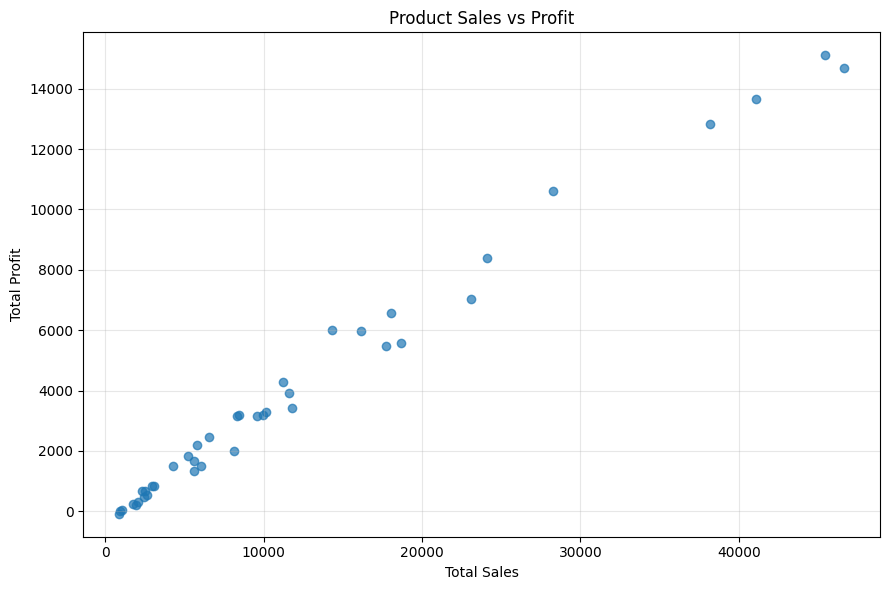

In [ ]:
#Sales vs Profit
plt.figure(figsize=(9, 6))

plt.scatter(
    product_performance['Total_Sales'],
    product_performance['Total_Profit'],
    alpha=0.7
)

plt.title('Product Sales vs Profit')
plt.xlabel('Total Sales')
plt.ylabel('Total Profit')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
sales_median = product_performance['Total_Sales'].median()
margin_median = product_performance['Profit_Margin_%'].median()

high_sales_low_margin = product_performance[
    (product_performance['Total_Sales'] > sales_median) &
    (product_performance['Profit_Margin_%'] < margin_median)
].sort_values(
    'Total_Sales',
    ascending=False
)

high_sales_low_margin

,Product_Name,Total_Sales,Total_Profit,Quantity_Sold,Total_Orders,Profit_Margin_%
10,Filing Cabinet 3-Drawer,23108.01,7041.80,170,45,30.473416
12,Folding Table Portable,18663.13,5589.03,226,57,29.946906
2,Bookshelf 5-Tier,17741.59,5490.57,154,55,30.947452
11,Floating Wall Shelves Set,11767.30,3407.42,193,57,28.956685


Final Business Finding

In [ ]:
#Best & Worst Business Finding
category_summary = (
    df.groupby('Product_Category')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

category_summary['Profit_Margin_%'] = (
    category_summary['Total_Profit'] /
    category_summary['Total_Sales'] * 100
)

category_summary.sort_values(
    'Total_Sales',
    ascending=False
)

,Product_Category,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
1,Furniture,256274.68,81171.57,507,31.673660
3,Technology,139518.22,48268.65,567,34.596664
0,Clothing & Accessories,69375.63,26112.94,413,37.639932
2,Office Supplies,19390.81,3319.16,513,17.117181


In [ ]:
#Best Performing Region
region_summary = (
    df.groupby('Region')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

region_summary['Profit_Margin_%'] = (
    region_summary['Total_Profit'] /
    region_summary['Total_Sales'] * 100
)

region_summary.sort_values(
    'Total_Sales',
    ascending=False
)

,Region,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
1,Europe,137006.20,45672.16,503,33.335834
3,North America,133876.38,45250.09,578,33.799906
0,Asia Pacific,121707.51,39116.61,520,32.139849
4,South America,46051.13,14680.98,191,31.879739
2,Middle East & Africa,45918.12,14152.48,208,30.821122


In [ ]:
#Best Customer Segment
segment_summary = (
    df.groupby('Customer_Segment')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Total_Customers=('Customer_Name', 'nunique')
    )
    .reset_index()
)

segment_summary['Average_Order_Value'] = (
    segment_summary['Total_Sales'] /
    segment_summary['Total_Orders']
)

segment_summary.sort_values(
    'Total_Sales',
    ascending=False
)

,Customer_Segment,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Average_Order_Value
0,Consumer,256287.74,87300.36,1006,864,254.759185
1,Corporate,146050.39,44463.44,623,558,234.430803
2,Home Office,82221.21,27108.52,371,355,221.620512


In [ ]:
#Top & Bottom Products
product_performance.sort_values(
    'Total_Sales',
    ascending=False
).head(10)[
    [
        'Product_Name',
        'Total_Sales',
        'Total_Profit',
        'Profit_Margin_%'
    ]
]

,Product_Name,Total_Sales,Total_Profit,Profit_Margin_%
28,Standing Desk Converter,46614.22,14694.35,31.523321
9,Ergonomic Office Chair,45405.15,15104.58,33.266226
5,Corner L-Shaped Desk,41070.48,13663.00,33.267203
18,Mesh Back Task Chair,38179.77,12820.11,33.578280
37,Wireless Bluetooth Headphones,28258.70,10611.08,37.549781
17,Mechanical Gaming Keyboard,24072.42,8381.19,34.816566
10,Filing Cabinet 3-Drawer,23108.01,7041.80,30.473416
12,Folding Table Portable,18663.13,5589.03,29.946906
23,Portable External SSD 1TB,18065.30,6556.75,36.294720
2,Bookshelf 5-Tier,17741.59,5490.57,30.947452


In [ ]:
#Top 10 Bottom Sales
product_performance.sort_values(
    'Total_Sales',
    ascending=True
).head(10)[
    [
        'Product_Name',
        'Total_Sales',
        'Total_Profit',
        'Profit_Margin_%'
    ]
]

,Product_Name,Total_Sales,Total_Profit,Profit_Margin_%
21,Paper Clips Box 500pc,901.89,-79.95,-8.864717
13,Highlighters Neon Pack 6,942.61,-0.37,-0.039253
30,Sticky Notes Multicolor 6-Pack,1072.27,61.90,5.772800
0,Ballpoint Pen Pack 12,1760.36,254.45,14.454430
1,Binder Clips Assorted 48pc,1924.59,214.49,11.144711
36,Whiteboard Markers Set 8,2090.67,311.95,14.921054
25,Silk Tie Collection,2307.23,667.04,28.910858
7,Desk Calendar 2025,2481.21,489.92,19.745205
24,Premium Notebook Set A5,2536.17,665.31,26.232863
29,Stapler Full-Size,2622.15,544.94,20.782183


Customer Concentration

In [ ]:
customer_sales = (
    df.groupby('Customer_Name')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)

top10_customer_sales = customer_sales.head(10).sum()

top10_customer_contribution = (
    top10_customer_sales /
    customer_sales.sum() * 100
)

print(
    f"Top 10 Customer Contribution: "
    f"{top10_customer_contribution:.2f}%"
)

Top 10 Customer Contribution: 6.35%


In [ ]:
#Average Order Value Per Segment
segment_aov = (
    df.groupby('Customer_Segment')
    .agg(
        Total_Sales=('Total_Sales', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .reset_index()
)

segment_aov['Average_Order_Value'] = (
    segment_aov['Total_Sales'] /
    segment_aov['Total_Orders']
)

segment_aov.sort_values(
    'Average_Order_Value',
    ascending=False
)

,Customer_Segment,Total_Sales,Total_Orders,Average_Order_Value
0,Consumer,256287.74,1006,254.759185
1,Corporate,146050.39,623,234.430803
2,Home Office,82221.21,371,221.620512


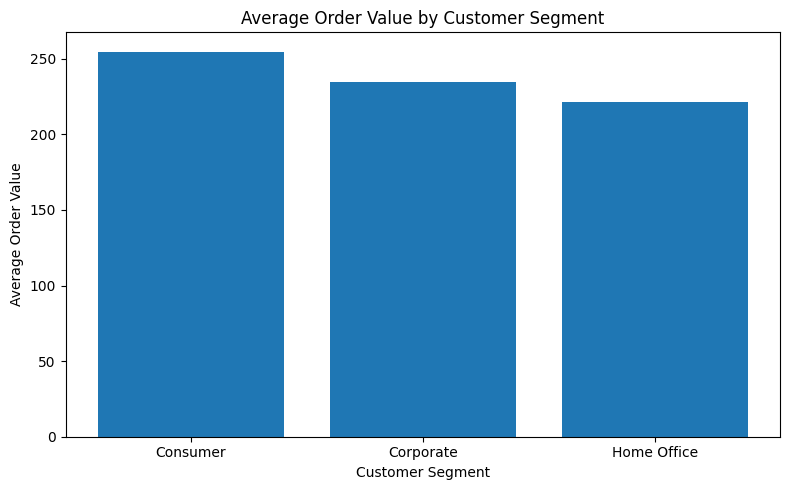

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_aov['Customer_Segment'],
    segment_aov['Average_Order_Value']
)

plt.title('Average Order Value by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Order Value')

plt.tight_layout()
plt.show()

In [ ]:
#Order Volume Trend
monthly_orders = (
    df.groupby('Month_Year')['Order_ID']
    .nunique()
    .reset_index(name='Total_Orders')
)

monthly_orders.head()

,Month_Year,Total_Orders
0,2023-01,47
1,2023-02,52
2,2023-03,51
3,2023-04,48
4,2023-05,40


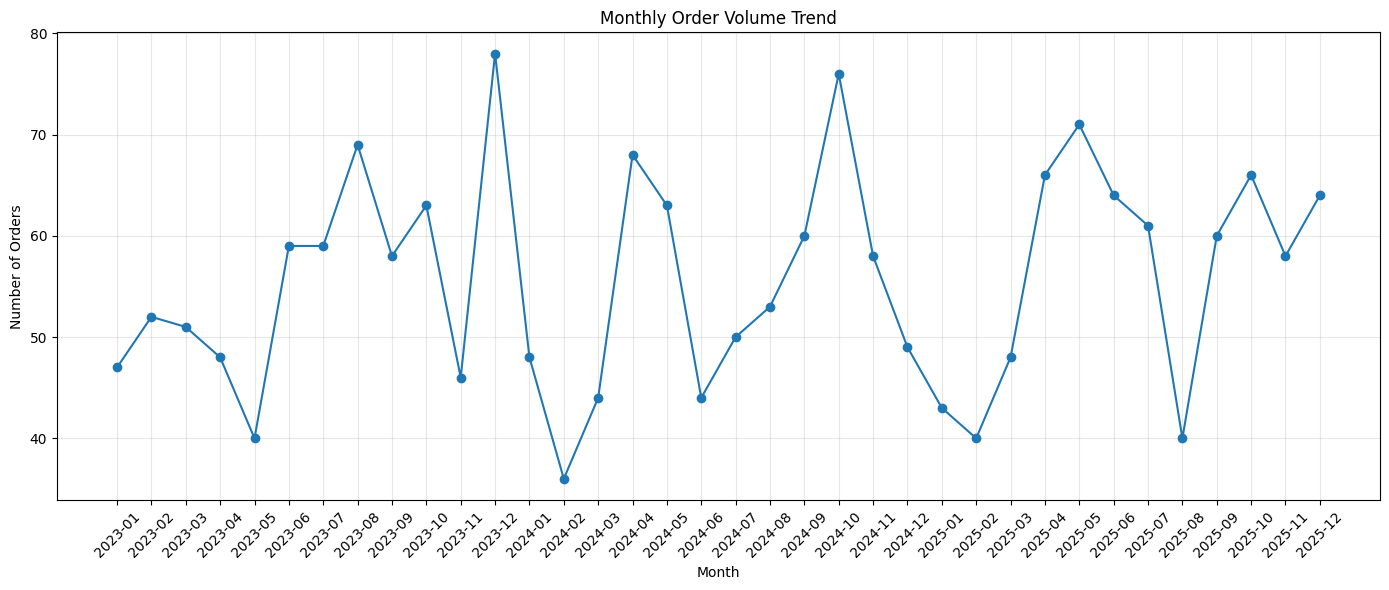

In [ ]:
plt.figure(figsize=(14, 6))

# Convert Month_Year to string to prevent Matplotlib Period TypeError
plt.plot(
    monthly_orders['Month_Year'].astype(str),
    monthly_orders['Total_Orders'],
    marker='o'
)

plt.title('Monthly Order Volume Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Final Summary

In [ ]:
best_category_sales = category_summary.loc[
    category_summary['Total_Sales'].idxmax()
]

best_category_profit = category_summary.loc[
    category_summary['Total_Profit'].idxmax()
]

best_region = region_summary.loc[
    region_summary['Total_Sales'].idxmax()
]

best_segment = segment_summary.loc[
    segment_summary['Total_Sales'].idxmax()
]

best_product = product_performance.loc[
    product_performance['Total_Sales'].idxmax()
]

best_month = monthly_sales.loc[
    monthly_sales['Total_Sales'].idxmax()
]

print("===== KEY BUSINESS FINDINGS =====")

print(
    f"Highest Sales Category : "
    f"{best_category_sales['Product_Category']} "
    f"(${best_category_sales['Total_Sales']:,.2f})"
)

print(
    f"Highest Profit Category: "
    f"{best_category_profit['Product_Category']} "
    f"(${best_category_profit['Total_Profit']:,.2f})"
)

print(
    f"Top Region            : "
    f"{best_region['Region']} "
    f"(${best_region['Total_Sales']:,.2f})"
)

print(
    f"Top Customer Segment  : "
    f"{best_segment['Customer_Segment']} "
    f"(${best_segment['Total_Sales']:,.2f})"
)

print(
    f"Top Product           : "
    f"{best_product['Product_Name']} "
    f"(${best_product['Total_Sales']:,.2f})"
)

print(
    f"Best Sales Month      : "
    f"{best_month['Month_Year']} "
    f"(${best_month['Total_Sales']:,.2f})"
)

print(
    f"Top 10 Customer Contribution: "
    f"{top10_customer_contribution:.2f}%"
)

print(
    f"Discount vs Profit Correlation: "
    f"{df['Discount_Percent'].corr(df['Profit']):.3f}"
)

print(
    f"Shipping Cost vs Profit Correlation: "
    f"{df['Shipping_Cost'].corr(df['Profit']):.3f}"
)

===== KEY BUSINESS FINDINGS =====
Highest Sales Category : Furniture ($256,274.68)
Highest Profit Category: Furniture ($81,171.57)
Top Region            : Europe ($137,006.20)
Top Customer Segment  : Consumer ($256,287.74)
Top Product           : Standing Desk Converter ($46,614.22)
Best Sales Month      : 2025-06 ($18,068.09)
Top 10 Customer Contribution: 6.35%
Discount vs Profit Correlation: -0.141
Shipping Cost vs Profit Correlation: 0.364


In [ ]:
# Calculate individual transaction profit margin first to avoid KeyError
df['Profit_Margin'] = (df['Profit'] / df['Total_Sales']) * 100

numeric_cols = [
    'Quantity',
    'Unit_Price',
    'Discount_Percent',
    'Total_Sales',
    'Shipping_Cost',
    'Profit',
    'Profit_Margin'
]

correlation_matrix = df[numeric_cols].corr()
correlation_matrix

,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Profit_Margin
Quantity,1.000000,0.020364,0.005010,0.503233,0.766924,0.503155,0.302833
Unit_Price,0.020364,1.000000,0.021263,0.701605,0.017095,0.666903,0.327859
Discount_Percent,0.005010,0.021263,1.000000,-0.045900,0.015693,-0.141340,-0.222276
Total_Sales,0.503233,0.701605,-0.045900,1.000000,0.385902,0.979217,0.289629
Shipping_Cost,0.766924,0.017095,0.015693,0.385902,1.000000,0.363832,0.135132
Profit,0.503155,0.666903,-0.141340,0.979217,0.363832,1.000000,0.320798
Profit_Margin,0.302833,0.327859,-0.222276,0.289629,0.135132,0.320798,1.000000


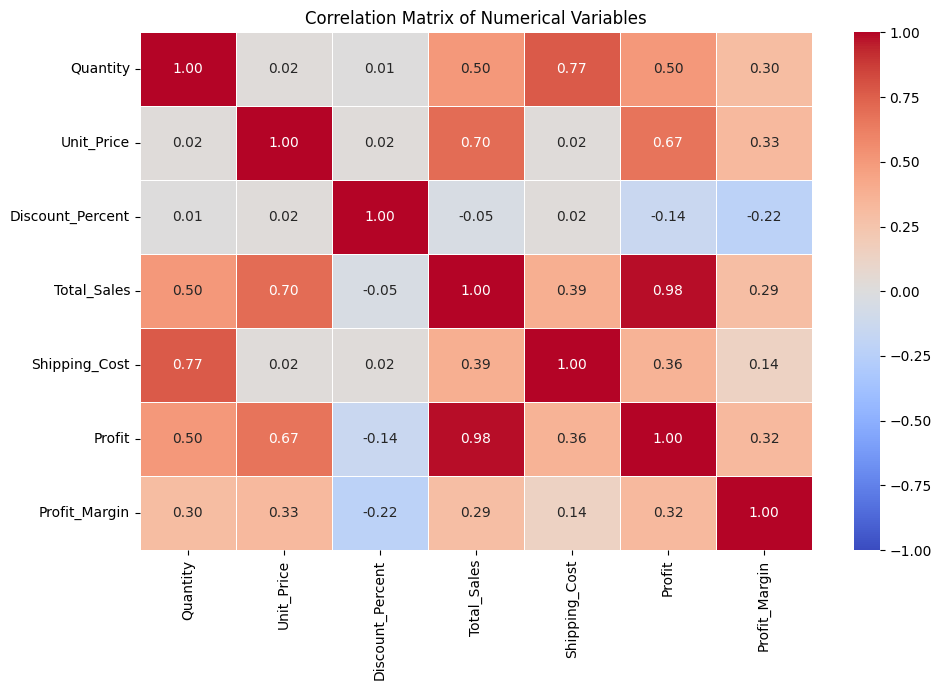

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

In [ ]:
#ranking korelasi
profit_correlation = (
    correlation_matrix['Profit']
    .drop('Profit')
    .sort_values(ascending=False)
)

profit_correlation

,Profit
Total_Sales,0.979217
Unit_Price,0.666903
Quantity,0.503155
Shipping_Cost,0.363832
Profit_Margin,0.320798
Discount_Percent,-0.141340


In [ ]:
# Simpan dalam format CSV
df.to_csv(
    'global_ecommerce_clean.csv',
    index=False
)

# Simpan dalam format Excel
df.to_excel(
    'global_ecommerce_clean.xlsx',
    index=False
)

print("Dataset berhasil disimpan dalam format CSV dan Excel.")

Dataset berhasil disimpan dalam format CSV dan Excel.


In [ ]:
from google.colab import files

files.download('global_ecommerce_clean.csv')
files.download('global_ecommerce_clean.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>